# 🏦 Banco Central da República de Valória
## Diagnóstico Estatístico e Econométrico dos Indicadores Macroeconômicos (2005–2024)

**Centro Universitário Impacta – UNIIMPACTA** · Inferência Estatística e Análise de Dados · Prof. Msc. Kyung Moo Kim
**Exercício Programa (EP) Individual** · Aluno(a): *[inserir nome e RA]*

---
**Como usar este notebook:** execute *Ambiente de execução → Executar tudo*. A primeira célula de código gera automaticamente o arquivo `dados_macroeconomicos_valoria.xlsx` (seed = 42), conforme exigido na seção 7 do enunciado. Todo o texto interpretativo (Markdown) foi redigido com base nos resultados obtidos com essa semente e é **conferido automaticamente** pela célula de síntese que antecede o informe.

**Nível de significância:** α = 0,05 em todos os testes. **Nota metodológica:** Valória e os dados são fictícios/simulados; os resultados demonstram métodos estatísticos e não constituem evidência sobre uma economia real.

### 🗺️ Mapa do notebook (critérios de avaliação do EP)
| Critério | Conteúdo | Peso | Seção |
|---|---|---|---|
| 1 | Ingestão, qualidade dos dados, descritiva, gráficos e tendência temporal | 1,5 | Módulo 1 |
| 2 | Shapiro-Wilk e Qui-Quadrado de aderência | 1,5 | Módulo 2 |
| 3 | Levene, t de Student e Mann-Whitney U | 2,0 | Módulo 3 |
| 4 | ANOVA 1 fator e ANOVA 2 fatores com interação | 2,0 | Módulo 4 |
| 5 | Regressão simples, múltipla, R² ajustado e VIF | 2,0 | Módulo 5 |
| 6 | Storytelling (informe ao Ministro) e Colab | 1,0 | Seção 6 |

**Sumário**
0. Geração do dataset · 1. Descritiva · 2. Normalidade e aderência · 3. Testes para 2 grupos · 4. ANOVAs · 5. Regressões · 6. **Informe Executivo (Storytelling)**

## 0. Geração do Dataset (célula de abertura exigida pelo enunciado)

In [1]:
# ============================================================
# 0. GERAÇÃO DO DATASET OFICIAL (script fornecido no enunciado)
# ============================================================
import pandas as pd
import numpy as np

np.random.seed(42)
n_obs = 240  # 20 anos de dados mensais

# 'M' foi renomeado para 'ME' em versões recentes do pandas; o try/except garante compatibilidade
try:
    datas = pd.date_range(start='2005-01-01', periods=n_obs, freq='ME')
except ValueError:
    datas = pd.date_range(start='2005-01-01', periods=n_obs, freq='M')

regiao = np.random.choice(['Norte', 'Sul', 'Leste', 'Oeste'], size=n_obs)
periodo_politica = np.random.choice(['Antes_Reforma', 'Depois_Reforma'], size=n_obs)
meta_cumprida = np.random.choice(['Sim', 'Nao'], size=n_obs, p=[0.65, 0.35])

# Variáveis quantitativas
pib_crescimento = np.random.normal(loc=2.5, scale=1.2, size=n_obs)
inflacao = np.random.exponential(scale=3.0, size=n_obs)  # assimétrica
desemprego = 8.0 - 0.8 * pib_crescimento + np.random.normal(0, 0.8, size=n_obs)
taxa_juros = 4.0 + 1.2 * inflacao + np.random.normal(0, 0.5, size=n_obs)
investimento_estrangeiro = 100 + 15 * pib_crescimento - 2.5 * taxa_juros + np.random.normal(0, 10, size=n_obs)

df_gerado = pd.DataFrame({
    'Data': datas,
    'Regiao': regiao,
    'Periodo_Politica': periodo_politica,
    'Meta_Inflacao_Cumprida': meta_cumprida,
    'Crescimento_PIB': np.round(pib_crescimento, 2),
    'Inflacao': np.round(inflacao, 2),
    'Taxa_Desemprego': np.round(np.clip(desemprego, 1.0, 20.0), 2),
    'Taxa_Juros_Selic': np.round(np.clip(taxa_juros, 0.5, 25.0), 2),
    'Investimento_Estrangeiro_Mi': np.round(investimento_estrangeiro, 2)
})

df_gerado.to_excel('dados_macroeconomicos_valoria.xlsx', index=False)
print("Dataset 'dados_macroeconomicos_valoria.xlsx' gerado com sucesso!")

Dataset 'dados_macroeconomicos_valoria.xlsx' gerado com sucesso!


# MÓDULO 1 — Ingestão de Dados e Estatística Descritiva

In [2]:
# ------------------------------------------------------------
# Módulo 1.1 – Ingestão e inspeção inicial
# ------------------------------------------------------------
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.outliers_influence import variance_inflation_factor

import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
ALPHA = 0.05

df = pd.read_excel('dados_macroeconomicos_valoria.xlsx')
print('Dimensão do dataset:', df.shape)
print('\nValores ausentes por coluna:\n', df.isna().sum())
print('\nTipos de dados:\n', df.dtypes)
df.head(10)

Dimensão do dataset: (240, 9)

Valores ausentes por coluna:
 Data                           0
Regiao                         0
Periodo_Politica               0
Meta_Inflacao_Cumprida         0
Crescimento_PIB                0
Inflacao                       0
Taxa_Desemprego                0
Taxa_Juros_Selic               0
Investimento_Estrangeiro_Mi    0
dtype: int64

Tipos de dados:
 Data                           datetime64[us]
Regiao                                    str
Periodo_Politica                          str
Meta_Inflacao_Cumprida                    str
Crescimento_PIB                       float64
Inflacao                              float64
Taxa_Desemprego                       float64
Taxa_Juros_Selic                      float64
Investimento_Estrangeiro_Mi           float64
dtype: object


,Data,Regiao,Periodo_Politica,Meta_Inflacao_Cumprida,Crescimento_PIB,Inflacao,Taxa_Desemprego,Taxa_Juros_Selic,Investimento_Estrangeiro_Mi
0,2005-01-31,Leste,Depois_Reforma,Nao,4.2400,0.5000,4.6800,5.1400,157.8600
1,2005-02-28,Oeste,Antes_Reforma,Nao,3.6500,2.6500,4.7100,7.1600,146.4400
2,2005-03-31,Norte,Depois_Reforma,Nao,5.0800,2.1100,3.5900,6.4500,152.2700
3,2005-04-30,Leste,Antes_Reforma,Sim,1.5800,2.8400,6.4900,7.8500,90.7600
4,2005-05-31,Leste,Antes_Reforma,Sim,3.5500,0.0500,5.3400,4.3900,123.8600
5,2005-06-30,Oeste,Depois_Reforma,Nao,2.7200,6.1700,5.4400,10.6200,119.3400
6,2005-07-31,Norte,Antes_Reforma,Sim,5.1300,8.0700,4.9000,14.4200,129.8300
7,2005-08-31,Norte,Antes_Reforma,Nao,1.5300,2.5000,6.0600,7.6900,82.2000
8,2005-09-30,Leste,Antes_Reforma,Nao,1.4900,3.5800,6.6600,7.9800,106.3200
9,2005-10-31,Sul,Antes_Reforma,Nao,1.7800,7.6700,6.2200,13.4000,118.1300


### 1.1b Qualidade e preparação dos dados
Antes de qualquer estatística, verificamos se a base está íntegra: esquema de colunas oficial, duplicatas, valores ausentes, tipos corretos e categorias esperadas. Criamos também a variável auxiliar `Ano`, usada na análise de tendência (Módulo 1.6).

In [3]:
# ------------------------------------------------------------
# Módulo 1.1b – Verificação de qualidade e preparação
# ------------------------------------------------------------
colunas_oficiais = ['Data', 'Regiao', 'Periodo_Politica', 'Meta_Inflacao_Cumprida', 'Crescimento_PIB',
                    'Inflacao', 'Taxa_Desemprego', 'Taxa_Juros_Selic', 'Investimento_Estrangeiro_Mi']
assert set(colunas_oficiais) == set(df.columns), 'Esquema de colunas diferente do dicionário de dados!'
assert len(df) == 240, 'A base oficial deve ter 240 observações mensais.'

df['Data'] = pd.to_datetime(df['Data'], errors='coerce')
for c in ['Crescimento_PIB', 'Inflacao', 'Taxa_Desemprego', 'Taxa_Juros_Selic', 'Investimento_Estrangeiro_Mi']:
    df[c] = pd.to_numeric(df[c], errors='coerce')

n_dup = df.duplicated().sum()
n_nan = df.isna().sum().sum()
df['Ano'] = df['Data'].dt.year

print(f'Observações: {len(df)} | Duplicatas: {n_dup} | Valores ausentes: {n_nan}')
print(f"Período: {df['Data'].min():%Y-%m} a {df['Data'].max():%Y-%m}")
print('Regiões             :', sorted(df['Regiao'].unique()))
print('Períodos de política:', sorted(df['Periodo_Politica'].unique()))
print('Meta cumprida       :', sorted(df['Meta_Inflacao_Cumprida'].unique()))
print('\nConclusão: base íntegra — nenhuma limpeza adicional foi necessária.' if (n_dup == 0 and n_nan == 0)
      else '\nAtenção: removendo duplicatas/ausentes...')
if n_dup or n_nan:
    df = df.drop_duplicates().dropna().copy()

Observações: 240 | Duplicatas: 0 | Valores ausentes: 0
Período: 2005-01 a 2024-12
Regiões             : ['Leste', 'Norte', 'Oeste', 'Sul']
Períodos de política: ['Antes_Reforma', 'Depois_Reforma']
Meta cumprida       : ['Nao', 'Sim']

Conclusão: base íntegra — nenhuma limpeza adicional foi necessária.


In [4]:
# ------------------------------------------------------------
# Módulo 1.2 – Tabela de estatísticas descritivas completa
# ------------------------------------------------------------
quant = ['Crescimento_PIB', 'Inflacao', 'Taxa_Desemprego',
         'Taxa_Juros_Selic', 'Investimento_Estrangeiro_Mi']

desc = pd.DataFrame({
    'Média':            df[quant].mean(),
    'Mediana':          df[quant].median(),
    'Desvio-Padrão':    df[quant].std(ddof=1),
    'Variância':        df[quant].var(ddof=1),
    'IQR':              df[quant].quantile(0.75) - df[quant].quantile(0.25),
    'Mínimo':           df[quant].min(),
    'Máximo':           df[quant].max(),
    'Assimetria (Skew)': df[quant].skew(),
    'Curtose (excesso)': df[quant].kurt(),   # Fisher: normal = 0
})
display(desc.round(3))

print('\nFrequências das variáveis qualitativas:')
for c in ['Regiao', 'Periodo_Politica', 'Meta_Inflacao_Cumprida']:
    display(df[c].value_counts().rename_axis(c).to_frame('Frequência')
              .assign(Percentual=lambda t: 100 * t['Frequência'] / len(df)).round(1))

,Média,Mediana,Desvio-Padrão,Variância,IQR,Mínimo,Máximo,Assimetria (Skew),Curtose (excesso)
Crescimento_PIB,2.4560,2.4300,1.2350,1.5260,1.7100,-0.4700,6.1900,0.1420,-0.3010
Inflacao,2.8820,2.0350,2.8210,7.9600,3.1950,0.0100,17.3000,1.6570,3.5210
Taxa_Desemprego,6.1620,6.2650,1.2370,1.5310,1.7100,2.3700,9.3900,-0.0770,-0.1500
Taxa_Juros_Selic,7.4960,6.4950,3.4410,11.8440,3.6170,3.0100,24.9400,1.5910,3.3070
Investimento_Estrangeiro_Mi,119.1620,119.6800,22.9750,527.8660,30.8670,45.2000,178.1200,-0.1670,-0.0550



Frequências das variáveis qualitativas:


,Frequência,Percentual
Regiao,,
Oeste,67,27.9000
Leste,64,26.7000
Norte,55,22.9000
Sul,54,22.5000


,Frequência,Percentual
Periodo_Politica,,
Depois_Reforma,126,52.5000
Antes_Reforma,114,47.5000


,Frequência,Percentual
Meta_Inflacao_Cumprida,,
Sim,151,62.9000
Nao,89,37.1000


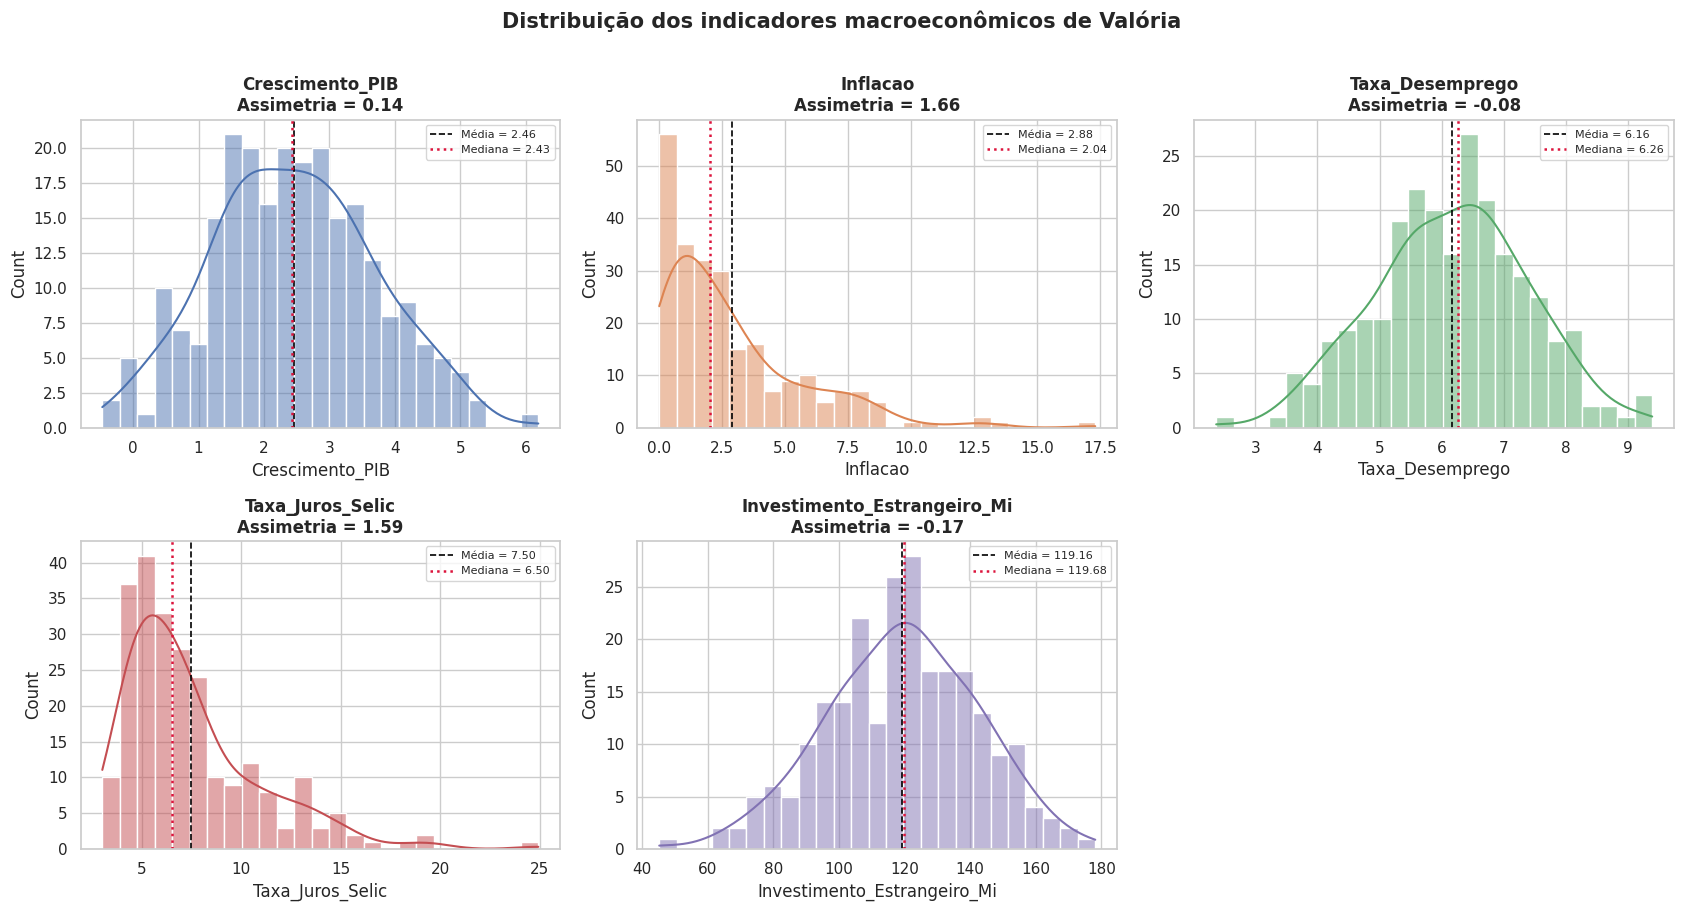

In [5]:
# ------------------------------------------------------------
# Módulo 1.3 – Histogramas com KDE
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
cores = sns.color_palette('deep', 5)
for ax, var, cor in zip(axes.ravel(), quant, cores):
    sns.histplot(df[var], kde=True, bins=25, color=cor, edgecolor='white', ax=ax)
    ax.axvline(df[var].mean(),   color='black', ls='--', lw=1.2, label=f'Média = {df[var].mean():.2f}')
    ax.axvline(df[var].median(), color='crimson', ls=':', lw=1.8, label=f'Mediana = {df[var].median():.2f}')
    ax.set_title(f'{var}\nAssimetria = {df[var].skew():.2f}', fontweight='bold')
    ax.legend(fontsize=8)
axes.ravel()[-1].axis('off')
plt.suptitle('Distribuição dos indicadores macroeconômicos de Valória', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()

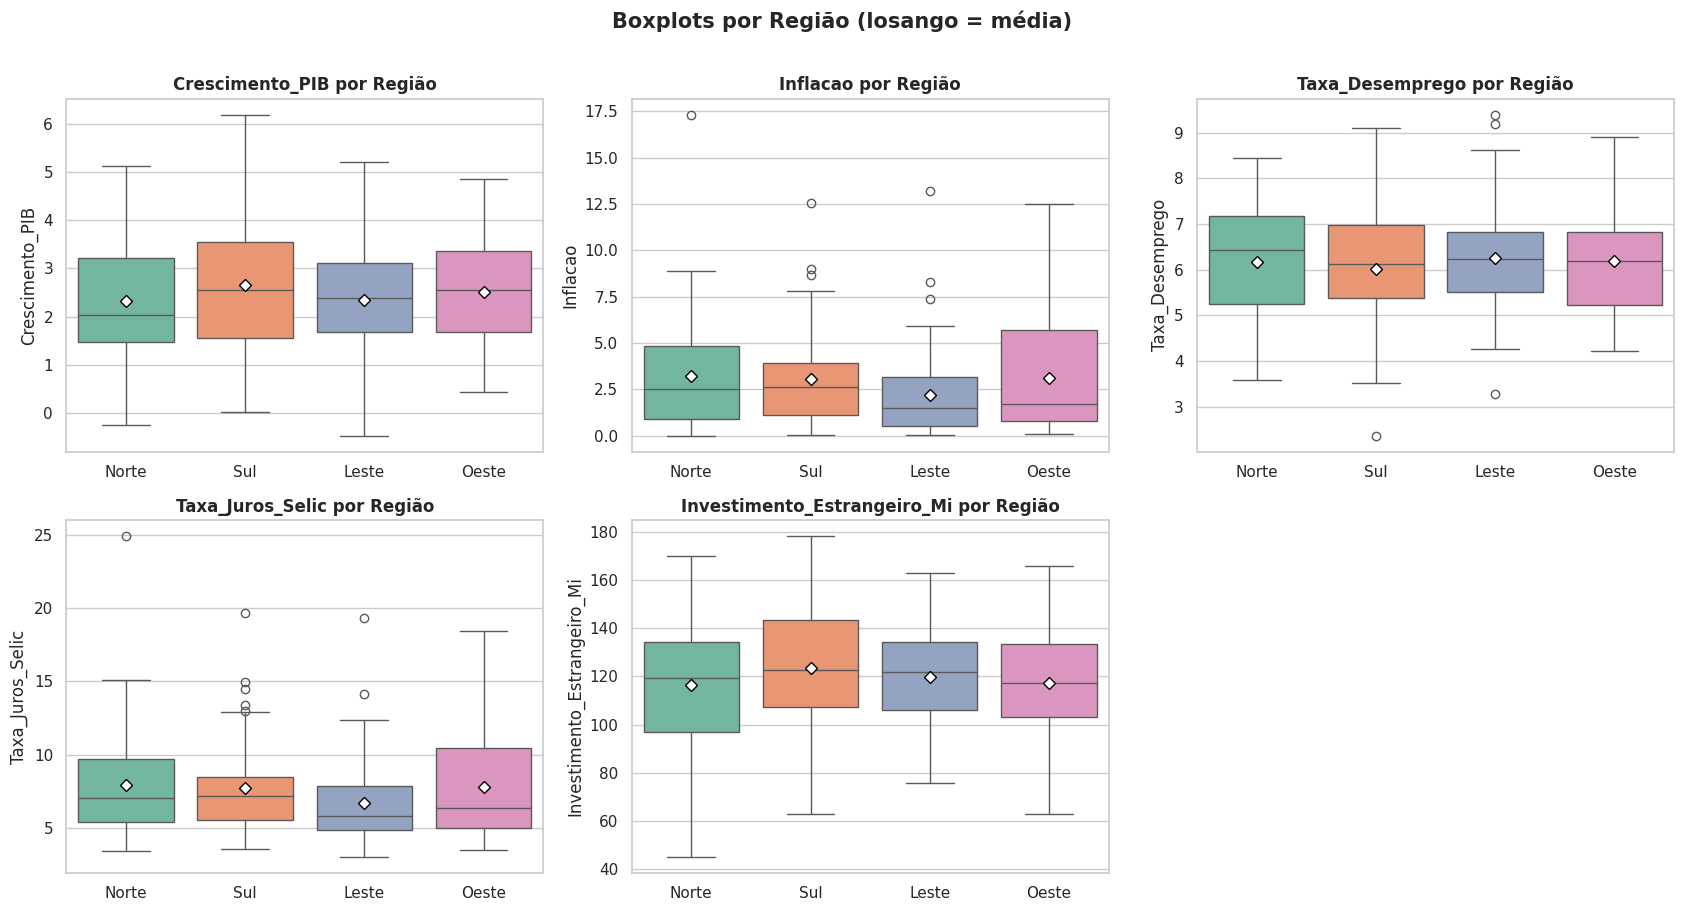

In [6]:
# ------------------------------------------------------------
# Módulo 1.4 – Boxplots por Região
# ------------------------------------------------------------
ordem = ['Norte', 'Sul', 'Leste', 'Oeste']
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, var in zip(axes.ravel(), quant):
    sns.boxplot(data=df, x='Regiao', y=var, order=ordem, palette='Set2', ax=ax, showmeans=True,
                meanprops={'marker': 'D', 'markerfacecolor': 'white', 'markeredgecolor': 'black'})
    ax.set_title(f'{var} por Região', fontweight='bold'); ax.set_xlabel('')
axes.ravel()[-1].axis('off')
plt.suptitle('Boxplots por Região (losango = média)', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()

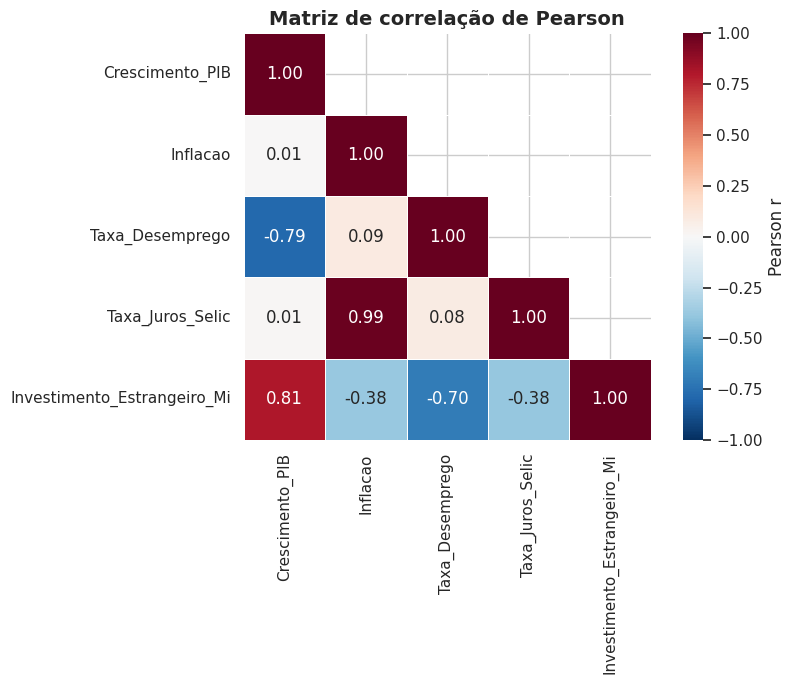

In [7]:
# ------------------------------------------------------------
# Módulo 1.5 – Matriz de correlação com Heatmap
# ------------------------------------------------------------
corr = df[quant].corr(method='pearson')
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, center=0,
            square=True, linewidths=.5, mask=mask, cbar_kws={'label': 'Pearson r'})
plt.title('Matriz de correlação de Pearson', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

### 1.6 Os indicadores apresentam tendência ao longo dos anos?
Para sustentar (ou descartar) afirmações sobre estabilidade, testamos a correlação de cada indicador com o `Ano` (Pearson e Spearman). A análise é exploratória e não substitui modelos de séries temporais.

* **H₀:** não há correlação entre o indicador e o ano (ρ = 0).
* **H₁:** há correlação entre o indicador e o ano (ρ ≠ 0).

,r de Pearson,p (Pearson),rho de Spearman,p (Spearman),"Decisão (α=0,05)"
Indicador,,,,,
Crescimento_PIB,-0.0320,0.6221,-0.0154,0.8130,Não rejeita H0 → sem tendência
Inflacao,0.0527,0.4160,0.0641,0.3227,Não rejeita H0 → sem tendência
Taxa_Desemprego,0.0165,0.7993,0.0238,0.7134,Não rejeita H0 → sem tendência
Taxa_Juros_Selic,0.0484,0.4558,0.0438,0.4996,Não rejeita H0 → sem tendência
Investimento_Estrangeiro_Mi,0.0085,0.8957,0.0038,0.9532,Não rejeita H0 → sem tendência


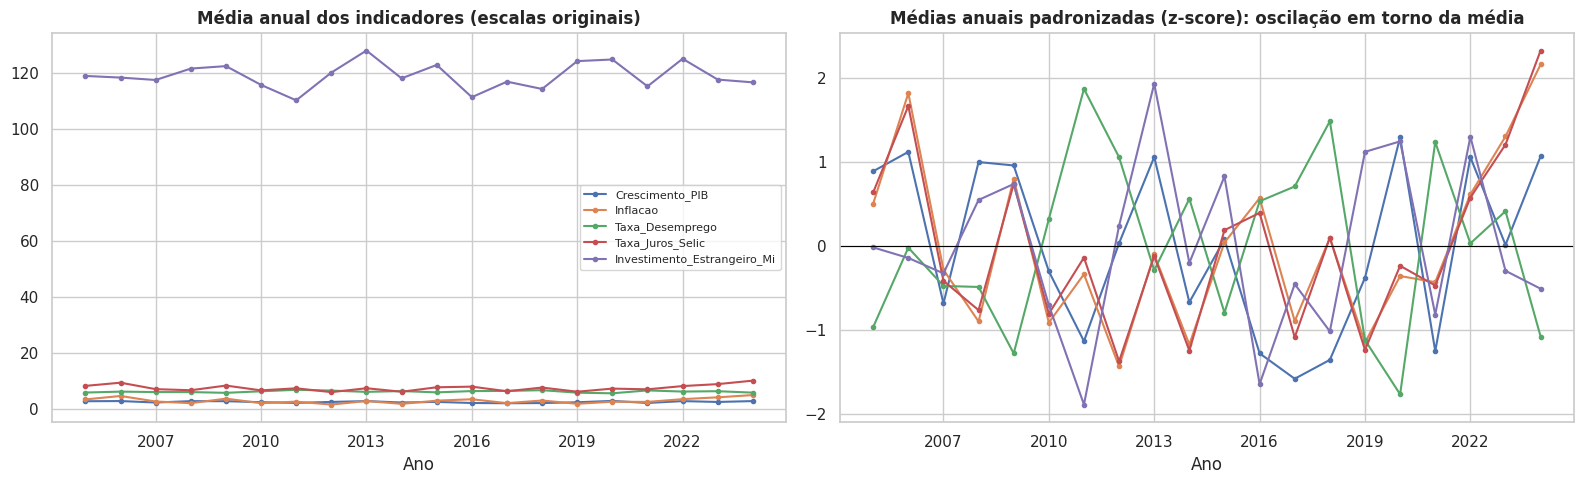

In [8]:
# ------------------------------------------------------------
# Módulo 1.6 – Tendência temporal (correlação com o Ano)
# ------------------------------------------------------------
linhas = []
for var in quant:
    r, p_r = stats.pearsonr(df['Ano'], df[var])
    rho, p_rho = stats.spearmanr(df['Ano'], df[var])
    linhas.append({'Indicador': var, 'r de Pearson': r, 'p (Pearson)': p_r,
                   'rho de Spearman': rho, 'p (Spearman)': p_rho,
                   'Decisão (α=0,05)': 'Rejeita H0 → há tendência' if min(p_r, p_rho) < ALPHA else 'Não rejeita H0 → sem tendência'})
tendencia = pd.DataFrame(linhas).set_index('Indicador')
display(tendencia.round(4))

# Média anual de cada indicador (padronizada para comparar escalas diferentes)
anual = df.groupby('Ano')[quant].mean()
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for var in quant:
    axes[0].plot(anual.index, anual[var], marker='o', ms=3, label=var)
axes[0].set_title('Média anual dos indicadores (escalas originais)', fontweight='bold')
axes[0].set_xlabel('Ano'); axes[0].legend(fontsize=8)
z = (anual - anual.mean()) / anual.std()
for var in quant:
    axes[1].plot(z.index, z[var], marker='o', ms=3, label=var)
axes[1].axhline(0, color='black', lw=.8)
axes[1].set_title('Médias anuais padronizadas (z-score): oscilação em torno da média', fontweight='bold')
axes[1].set_xlabel('Ano')
from matplotlib.ticker import MaxNLocator
for ax in axes: ax.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout(); plt.show()

**Conclusão (tendência):** nenhum indicador apresenta correlação significativa com o ano (todos os p-valores > 0,30, tanto em Pearson quanto em Spearman; |r| ≤ 0,07). Os indicadores **oscilam em torno de um nível estável** nos 20 anos — não há deriva de longo prazo no crescimento, na inflação, nos juros, no desemprego ou no investimento estrangeiro. Isso sustenta a leitura de estabilidade do informe.

### Leitura do Módulo 1
* **Crescimento do PIB** e **Taxa de Desemprego** são praticamente simétricos (assimetria ≈ 0,14 e −0,08) e com média ≈ mediana: comportamento próximo ao normal.
* **Inflação** e **Taxa Selic** são fortemente assimétricas à direita (assimetria ≈ 1,66 e 1,59; curtose em excesso ≈ 3,5 e 3,3), com média acima da mediana (2,88 vs. 2,04 para a inflação) — poucos meses de inflação muito alta puxam a média. Isso antecipa o uso de teste **não paramétrico** para a inflação.
* O heatmap revela três relações relevantes: **PIB × Desemprego (r ≈ −0,79)**, **PIB × Investimento Estrangeiro (r ≈ +0,81)** e **Inflação × Selic (r ≈ +0,99)**. Esta última é um alerta de **multicolinearidade** para o Módulo 5.
* Os boxplots por Região mostram medianas e dispersões muito semelhantes entre Norte, Sul, Leste e Oeste.
* **Tendência temporal (1.6):** nenhum indicador tem correlação significativa com o ano; a série é estacionária em nível, sem deriva de longo prazo.

# MÓDULO 2 — Testes de Normalidade e Aderência

### 2.1 Teste de Shapiro-Wilk
Para cada variável (`Crescimento_PIB` e `Inflacao`), com α = 0,05:

* **H₀:** a variável provém de uma população com distribuição normal.
* **H₁:** a variável **não** provém de uma população com distribuição normal.
* Regra: rejeita-se H₀ se p-valor < 0,05.

,W,p-valor,"Decisão (α=0,05)"
Variável,,,
Crescimento_PIB,0.9950,0.6223,Não rejeita H0 → compatível com normal
Inflacao,0.8391,0.0000,Rejeita H0 → NÃO normal


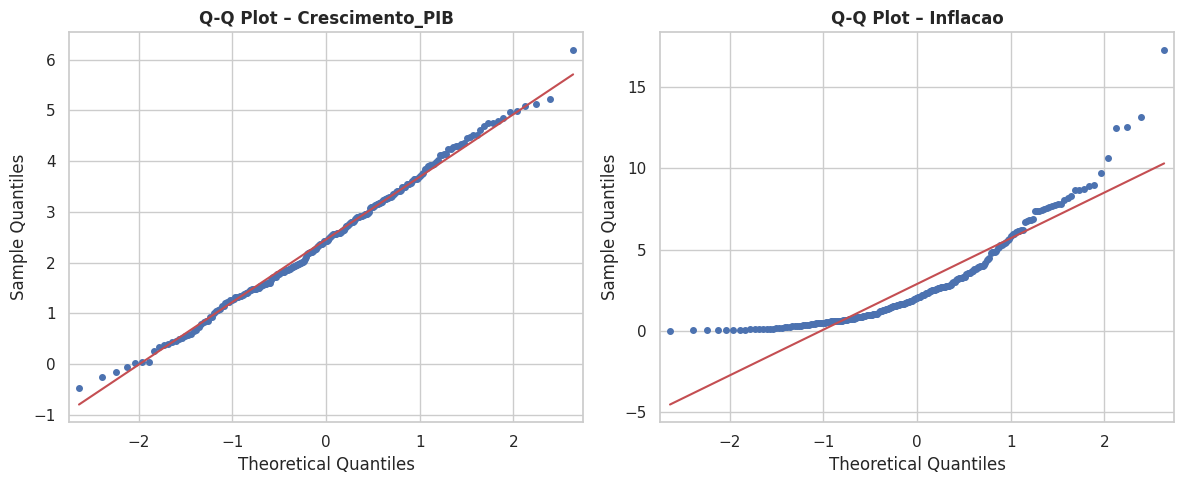

In [9]:
# ------------------------------------------------------------
# Módulo 2.1 – Shapiro-Wilk
# ------------------------------------------------------------
res_sw = []
for var in ['Crescimento_PIB', 'Inflacao']:
    W, p = stats.shapiro(df[var])
    res_sw.append({'Variável': var, 'W': W, 'p-valor': p,
                   'Decisão (α=0,05)': 'Rejeita H0 → NÃO normal' if p < ALPHA else 'Não rejeita H0 → compatível com normal'})
display(pd.DataFrame(res_sw).set_index('Variável'))

# Apoio visual: Q-Q plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, var in zip(axes, ['Crescimento_PIB', 'Inflacao']):
    sm.qqplot(df[var], line='s', ax=ax, markersize=4)
    ax.set_title(f'Q-Q Plot – {var}', fontweight='bold')
plt.tight_layout(); plt.show()

**Conclusão (Shapiro-Wilk):**
* `Crescimento_PIB`: W ≈ 0,995; **p ≈ 0,622 > 0,05** → não rejeitamos H₀; não há evidência contra a normalidade.
* `Inflacao`: W ≈ 0,839; **p ≈ 4,6 × 10⁻¹⁵ < 0,05** → rejeitamos H₀; a inflação **não é normal** (o Q-Q plot mostra a cauda direita pesada), o que justifica o teste de Mann-Whitney no Módulo 3.

### 2.2 Teste de Aderência do Qui-Quadrado (distribuição uniforme entre as Regiões)
* **H₀:** as observações estão distribuídas uniformemente entre as 4 regiões (p = 25% cada).
* **H₁:** pelo menos uma região tem proporção diferente de 25%.
* Estatística: χ² = Σ (O − E)² / E, com gl = k − 1 = 3. Frequência esperada: 240/4 = 60 por região (≥ 5, condição satisfeita).

,Observado,Esperado,(O-E)²/E
Regiao,,,
Norte,55,60.0000,0.4167
Sul,54,60.0000,0.6000
Leste,64,60.0000,0.2667
Oeste,67,60.0000,0.8167


χ² = 2.100 | gl = 3 | p-valor = 0.5519
Decisão: Não rejeita H0 → distribuição regional compatível com uniforme


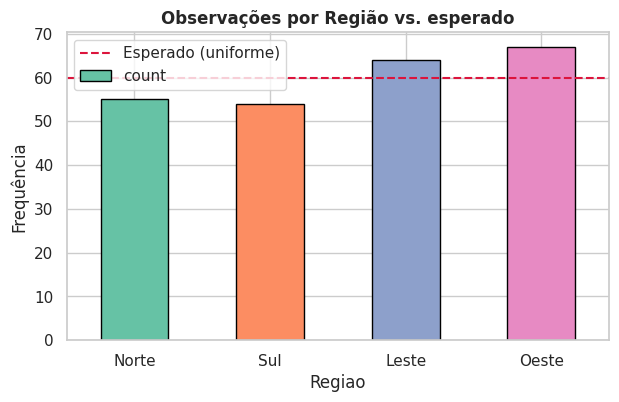

In [10]:
# ------------------------------------------------------------
# Módulo 2.2 – Qui-Quadrado de Aderência
# ------------------------------------------------------------
obs = df['Regiao'].value_counts().reindex(['Norte', 'Sul', 'Leste', 'Oeste'])
esp = np.full(4, obs.sum() / 4)
chi2, p_chi = stats.chisquare(f_obs=obs.values, f_exp=esp)

tab = pd.DataFrame({'Observado': obs, 'Esperado': esp, '(O-E)²/E': (obs - esp)**2 / esp})
display(tab)
print(f'χ² = {chi2:.3f} | gl = {len(obs)-1} | p-valor = {p_chi:.4f}')
print('Decisão:', 'Rejeita H0' if p_chi < ALPHA else 'Não rejeita H0 → distribuição regional compatível com uniforme')

ax = obs.plot(kind='bar', color=sns.color_palette('Set2'), edgecolor='black', figsize=(7, 4))
ax.axhline(esp[0], color='crimson', ls='--', label='Esperado (uniforme)')
ax.set_title('Observações por Região vs. esperado', fontweight='bold'); ax.set_ylabel('Frequência'); ax.legend()
plt.xticks(rotation=0); plt.show()

**Conclusão (Qui-Quadrado):** χ² = 2,10; gl = 3; **p ≈ 0,552 > 0,05** → não rejeitamos H₀. As contagens observadas (Norte 55, Sul 54, Leste 64, Oeste 67) são compatíveis com uma distribuição uniforme: a amostra **não está enviesada** para nenhuma região.

# MÓDULO 3 — Testes de Hipóteses para 2 Grupos

### 3.1 Teste de Levene (homocedasticidade) — `Crescimento_PIB` × `Periodo_Politica`
* **H₀:** σ²(Antes_Reforma) = σ²(Depois_Reforma).
* **H₁:** σ²(Antes_Reforma) ≠ σ²(Depois_Reforma).

> Observação técnica: o enunciado associa o Levene ao “Teste F de variâncias”. São testes distintos: o **Levene** é robusto à não normalidade; o **teste F** (razão de variâncias) exige normalidade. Como o PIB é normal (Módulo 2), executamos **ambos** como verificação cruzada.

In [11]:
# ------------------------------------------------------------
# Módulo 3.1 – Levene (+ teste F de razão de variâncias como complemento)
# ------------------------------------------------------------
antes  = df.loc[df['Periodo_Politica'] == 'Antes_Reforma',  'Crescimento_PIB']
depois = df.loc[df['Periodo_Politica'] == 'Depois_Reforma', 'Crescimento_PIB']

print(f'n(Antes) = {len(antes)} | n(Depois) = {len(depois)}')
print(f'Média: Antes = {antes.mean():.3f} | Depois = {depois.mean():.3f}')
print(f'Variância: Antes = {antes.var(ddof=1):.3f} | Depois = {depois.var(ddof=1):.3f}\n')

lev_stat, lev_p = stats.levene(antes, depois, center='mean')   # Levene clássico (centro = média)
bf_stat,  bf_p  = stats.levene(antes, depois, center='median') # Brown-Forsythe (centro = mediana)
print(f'Levene (média)          : W = {lev_stat:.4f} | p = {lev_p:.4f}')
print(f'Brown-Forsythe (mediana): W = {bf_stat:.4f} | p = {bf_p:.4f}')

F = antes.var(ddof=1) / depois.var(ddof=1)
d1, d2 = len(antes) - 1, len(depois) - 1
p_F = 2 * min(stats.f.cdf(F, d1, d2), stats.f.sf(F, d1, d2))
print(f'Teste F de variâncias   : F = {F:.4f} | p = {p_F:.4f}')
print('\nDecisão:', 'Rejeita H0 (variâncias diferentes)' if lev_p < ALPHA
      else 'Não rejeita H0 → variâncias homogêneas (usar t com variâncias iguais)')

n(Antes) = 114 | n(Depois) = 126
Média: Antes = 2.508 | Depois = 2.409
Variância: Antes = 1.355 | Depois = 1.688

Levene (média)          : W = 1.0156 | p = 0.3146
Brown-Forsythe (mediana): W = 1.0028 | p = 0.3176
Teste F de variâncias   : F = 0.8027 | p = 0.2348

Decisão: Não rejeita H0 → variâncias homogêneas (usar t com variâncias iguais)


**Conclusão (Levene):** W ≈ 1,016; **p ≈ 0,315 > 0,05** → não rejeitamos H₀. A volatilidade do crescimento é estatisticamente a mesma antes e depois da reforma (o teste F confirma: p ≈ 0,235). Está validado o pressuposto de variâncias iguais para o teste t.

### 3.2 Teste t de Student (amostras independentes) — `Crescimento_PIB` × `Periodo_Politica`
* **H₀:** μ(Antes_Reforma) = μ(Depois_Reforma).
* **H₁:** μ(Antes_Reforma) ≠ μ(Depois_Reforma) (bilateral).
* Pressupostos: independência, normalidade (Shapiro ✔) e homocedasticidade (Levene ✔).

t (variâncias iguais) = 0.6177 | gl = 238 | p = 0.5373
t de Welch (robustez)  = 0.6211 | p = 0.5351
Diferença de médias (Antes − Depois) = 0.099 p.p. | IC95% = [-0.216 ; 0.414]
d de Cohen = 0.080
Decisão: Não rejeita H0 → sem diferença significativa no crescimento médio


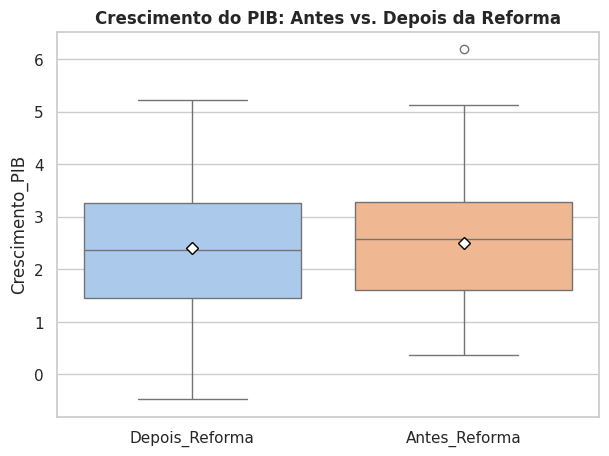

In [12]:
# ------------------------------------------------------------
# Módulo 3.2 – t de Student
# ------------------------------------------------------------
t_stat, t_p = stats.ttest_ind(antes, depois, equal_var=True)
tw_stat, tw_p = stats.ttest_ind(antes, depois, equal_var=False)   # Welch, como checagem de robustez

# Intervalo de confiança de 95% para a diferença de médias e d de Cohen
gl = len(antes) + len(depois) - 2
sp = np.sqrt(((len(antes)-1)*antes.var(ddof=1) + (len(depois)-1)*depois.var(ddof=1)) / gl)
dif = antes.mean() - depois.mean()
ep = sp * np.sqrt(1/len(antes) + 1/len(depois))
ic = (dif - stats.t.ppf(0.975, gl) * ep, dif + stats.t.ppf(0.975, gl) * ep)
d_cohen = dif / sp

print(f't (variâncias iguais) = {t_stat:.4f} | gl = {gl} | p = {t_p:.4f}')
print(f't de Welch (robustez)  = {tw_stat:.4f} | p = {tw_p:.4f}')
print(f'Diferença de médias (Antes − Depois) = {dif:.3f} p.p. | IC95% = [{ic[0]:.3f} ; {ic[1]:.3f}]')
print(f"d de Cohen = {d_cohen:.3f}")
print('Decisão:', 'Rejeita H0' if t_p < ALPHA else 'Não rejeita H0 → sem diferença significativa no crescimento médio')

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='Periodo_Politica', y='Crescimento_PIB', palette='pastel', showmeans=True,
            meanprops={'marker': 'D', 'markerfacecolor': 'white', 'markeredgecolor': 'black'})
plt.title('Crescimento do PIB: Antes vs. Depois da Reforma', fontweight='bold'); plt.xlabel('')
plt.show()

**Conclusão (teste t):** média Antes = 2,51% e Depois = 2,41%; t ≈ 0,618; gl = 238; **p ≈ 0,537 > 0,05** → não rejeitamos H₀. A diferença observada (~0,10 p.p.) é compatível com variação amostral: **não há evidência de que a reforma alterou o crescimento médio do PIB.** O resultado é robusto ao teste de Welch (p ≈ 0,535).

### 3.3 Teste U de Mann-Whitney — `Inflacao` × `Meta_Inflacao_Cumprida`
Como a inflação não é normal (Shapiro, p ≈ 10⁻¹⁵), usa-se o teste não paramétrico.
* **H₀:** as distribuições da inflação são iguais nos meses com meta cumprida (“Sim”) e não cumprida (“Nao”).
* **H₁:** as distribuições diferem (um grupo tende a ter valores sistematicamente maiores que o outro).

n(Sim) = 151 | n(Nao) = 89
Mediana: Sim = 2.02 | Nao = 2.05
U = 6873.0 | p-valor = 0.7684
Tamanho de efeito (correlação bisserial por postos; + = Sim tende a ser maior) = 0.023
Decisão: Não rejeita H0 → distribuições de inflação indistinguíveis


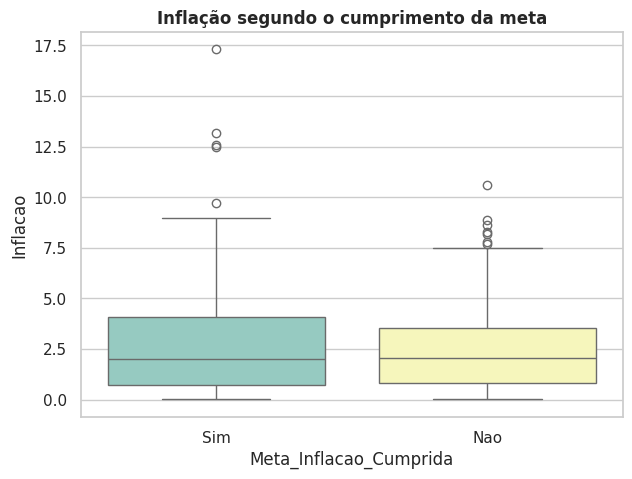

In [13]:
# ------------------------------------------------------------
# Módulo 3.3 – Mann-Whitney U
# ------------------------------------------------------------
sim = df.loc[df['Meta_Inflacao_Cumprida'] == 'Sim', 'Inflacao']
nao = df.loc[df['Meta_Inflacao_Cumprida'] == 'Nao', 'Inflacao']
U, p_u = stats.mannwhitneyu(sim, nao, alternative='two-sided')

print(f'n(Sim) = {len(sim)} | n(Nao) = {len(nao)}')
print(f'Mediana: Sim = {sim.median():.2f} | Nao = {nao.median():.2f}')
print(f'U = {U:.1f} | p-valor = {p_u:.4f}')
print(f'Tamanho de efeito (correlação bisserial por postos; + = Sim tende a ser maior) = {2*U/(len(sim)*len(nao)) - 1:.3f}')
print('Decisão:', 'Rejeita H0' if p_u < ALPHA else 'Não rejeita H0 → distribuições de inflação indistinguíveis')

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='Meta_Inflacao_Cumprida', y='Inflacao', order=['Sim', 'Nao'], palette='Set3')
plt.title('Inflação segundo o cumprimento da meta', fontweight='bold'); plt.show()

**Conclusão (Mann-Whitney):** medianas de 2,02 (Sim) e 2,05 (Nao); U = 6.873; **p ≈ 0,768 > 0,05** → não rejeitamos H₀. O fato de a meta ter sido declarada cumprida **não está associado** a diferenças na inflação observada — achado que merece atenção do Conselho quanto ao próprio critério de apuração da meta.

# MÓDULO 4 — Análise de Variância (ANOVA)

### 4.1 ANOVA de Um Fator — `Taxa_Desemprego` × `Regiao`
* **H₀:** μ_Norte = μ_Sul = μ_Leste = μ_Oeste.
* **H₁:** pelo menos uma média regional difere das demais.

,count,mean,std
Regiao,,,
Leste,64,6.2630,1.1470
Norte,55,6.1610,1.3390
Oeste,67,6.1860,1.1720
Sul,54,6.0120,1.3300


,gl,Soma de Quadrados,Quadrado Médio,Estatística F,p-valor
C(Regiao),3.0000,1.9144,0.6381,0.4137,0.7433
Residual,236.0000,364.0221,1.5425,NaN,NaN


Levene entre regiões        : p = 0.3442
Shapiro dos resíduos        : p = 0.9084
Conferência scipy.f_oneway   : F = 0.4137 | p = 0.7433


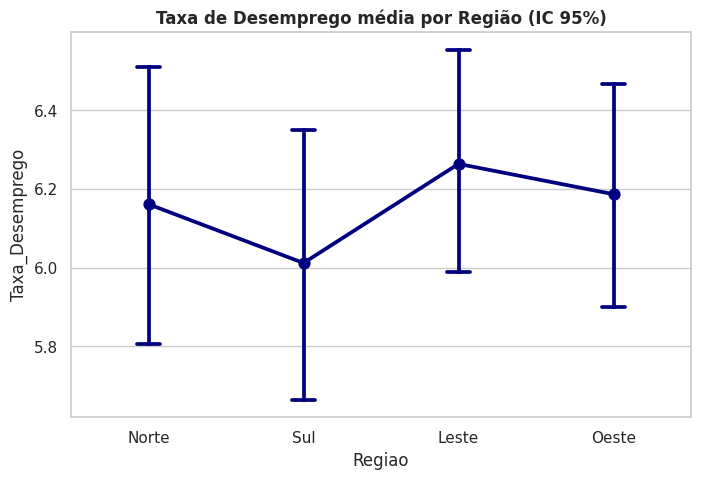

In [14]:
# ------------------------------------------------------------
# Módulo 4.1 – One-Way ANOVA
# ------------------------------------------------------------
display(df.groupby('Regiao')['Taxa_Desemprego'].agg(['count', 'mean', 'std']).round(3))

mod1 = smf.ols('Taxa_Desemprego ~ C(Regiao)', data=df).fit()
tab1 = anova_lm(mod1, typ=1)
tab1.columns = ['gl', 'Soma de Quadrados', 'Quadrado Médio', 'Estatística F', 'p-valor']
display(tab1)

# Verificação dos pressupostos
print('Levene entre regiões        : p =', round(stats.levene(*[g['Taxa_Desemprego'].values for _, g in df.groupby('Regiao')])[1], 4))
print('Shapiro dos resíduos        : p =', round(stats.shapiro(mod1.resid)[1], 4))
# Conferência com scipy
F1, p1 = stats.f_oneway(*[g['Taxa_Desemprego'].values for _, g in df.groupby('Regiao')])
print(f'Conferência scipy.f_oneway   : F = {F1:.4f} | p = {p1:.4f}')

plt.figure(figsize=(8, 5))
sns.pointplot(data=df, x='Regiao', y='Taxa_Desemprego', order=['Norte', 'Sul', 'Leste', 'Oeste'],
              errorbar=('ci', 95), capsize=.15, color='navy')
plt.title('Taxa de Desemprego média por Região (IC 95%)', fontweight='bold'); plt.show()

**Conclusão (ANOVA 1 fator):** F(3; 236) ≈ 0,414; **p ≈ 0,743 > 0,05** → não rejeitamos H₀. As médias regionais (Leste 6,26; Oeste 6,19; Norte 6,16; Sul 6,01) não diferem significativamente; as variâncias são homogêneas (Levene p ≈ 0,344). **Não há desigualdade regional de desemprego estatisticamente comprovada**, logo não se justificam, com base nestes dados, políticas de emprego regionalmente diferenciadas. Como H₀ não foi rejeitada, comparações múltiplas pós-hoc (Tukey) não são necessárias.

### 4.2 ANOVA de Dois Fatores com Interação — `Investimento_Estrangeiro_Mi` ~ `Regiao` × `Periodo_Politica`
Três pares de hipóteses:
* **Efeito de Região:** H₀: as médias de investimento são iguais entre as regiões · H₁: ao menos uma difere.
* **Efeito de Período:** H₀: μ(Antes) = μ(Depois) · H₁: μ(Antes) ≠ μ(Depois).
* **Interação Região × Período:** H₀: o efeito da reforma é o mesmo em todas as regiões (não há interação) · H₁: o efeito da reforma depende da região.

> O desenho é **desbalanceado** (n por célula entre 21 e 37). Por isso usamos a soma de quadrados **Tipo II**, apropriada quando a interação não é significativa; a interação é testada primeiro.

count     mean     std
Regiao Periodo_Politica                        
Leste  Antes_Reforma        32 123.7400 15.2300
       Depois_Reforma       32 115.4800 22.1500
Norte  Antes_Reforma        21 115.8900 27.0700
       Depois_Reforma       34 117.0200 24.4800
Oeste  Antes_Reforma        37 115.4800 22.9300
       Depois_Reforma       30 119.8200 20.9900
Sul    Antes_Reforma        24 123.3100 29.7400
       Depois_Reforma       30 123.5000 22.2100

,Soma de Quadrados,gl,Estatística F,p-valor
C(Regiao),"1,560.6266",3.0000,0.9798,0.4030
C(Periodo_Politica),31.3573,1.0000,0.0591,0.8082
C(Regiao):C(Periodo_Politica),"1,390.6818",3.0000,0.8731,0.4557
Residual,"123,180.7609",232.0000,NaN,NaN


Levene entre as 8 células  : p = 0.0841
Shapiro dos resíduos       : p = 0.9278


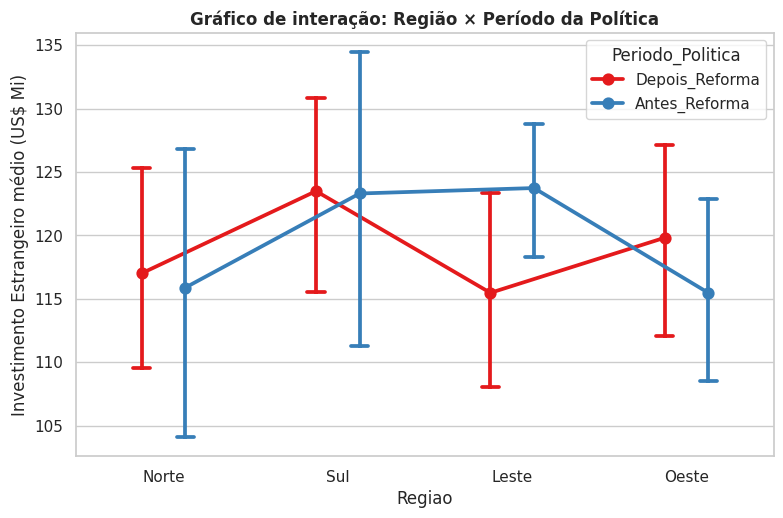

In [15]:
# ------------------------------------------------------------
# Módulo 4.2 – Two-Way ANOVA com interação
# ------------------------------------------------------------
display(df.groupby(['Regiao', 'Periodo_Politica'])['Investimento_Estrangeiro_Mi']
          .agg(['count', 'mean', 'std']).round(2))

mod2 = smf.ols('Investimento_Estrangeiro_Mi ~ C(Regiao) * C(Periodo_Politica)', data=df).fit()
tab2 = anova_lm(mod2, typ=2)
tab2.columns = ['Soma de Quadrados', 'gl', 'Estatística F', 'p-valor']
display(tab2)

# Pressupostos
cel = [g['Investimento_Estrangeiro_Mi'].values for _, g in df.groupby(['Regiao', 'Periodo_Politica'])]
print('Levene entre as 8 células  : p =', round(stats.levene(*cel)[1], 4))
print('Shapiro dos resíduos       : p =', round(stats.shapiro(mod2.resid)[1], 4))

# Gráfico de interação
plt.figure(figsize=(9, 5.5))
sns.pointplot(data=df, x='Regiao', y='Investimento_Estrangeiro_Mi', hue='Periodo_Politica',
              order=['Norte', 'Sul', 'Leste', 'Oeste'], dodge=.25, capsize=.1, errorbar=('ci', 95), palette='Set1')
plt.title('Gráfico de interação: Região × Período da Política', fontweight='bold')
plt.ylabel('Investimento Estrangeiro médio (US$ Mi)'); plt.show()

**Interpretação do F-teste de interação:** F(3; 232) ≈ 0,873; **p ≈ 0,456 > 0,05** → não rejeitamos H₀ de ausência de interação. Graficamente, as linhas dos dois períodos não apresentam um padrão sistemático de cruzamento: o efeito da reforma **não depende da região**. As aparentes diferenças em Leste (−8,3 US$ Mi) e Oeste (+4,3 US$ Mi) estão dentro do ruído amostral (desvio-padrão residual ≈ 23 US$ Mi).

**Efeitos principais (Tipo II):** Região, F ≈ 0,980, p ≈ 0,403; Período, F ≈ 0,059, p ≈ 0,808. Nenhum fator isolado afeta significativamente o investimento estrangeiro. O Levene entre células (p ≈ 0,084) não indica violação grave de homocedasticidade.

# MÓDULO 5 — Modelagem Econométrica

### 5.1 Regressão Linear Simples — `Taxa_Desemprego` (Y) ~ `Crescimento_PIB` (X)
**Modelo:** Y = β₀ + β₁·X + ε
* **H₀ (teste F global / teste t de β₁):** β₁ = 0 (o PIB não explica o desemprego) · **H₁:** β₁ ≠ 0.

                            OLS Regression Results                            
Dep. Variable:        Taxa_Desemprego   R-squared:                       0.618
Model:                            OLS   Adj. R-squared:                  0.616
Method:                 Least Squares   F-statistic:                     384.3
Date:                Thu, 22 Oct 2026   Prob (F-statistic):           1.38e-51
Time:                        01:22:53   Log-Likelihood:                -275.82
No. Observations:                 240   AIC:                             555.6
Df Residuals:                     238   BIC:                             562.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               8.0949      0.110     


Conferência sklearn → β0 = 8.0949 | β1 = -0.7871 | R² = 0.6176


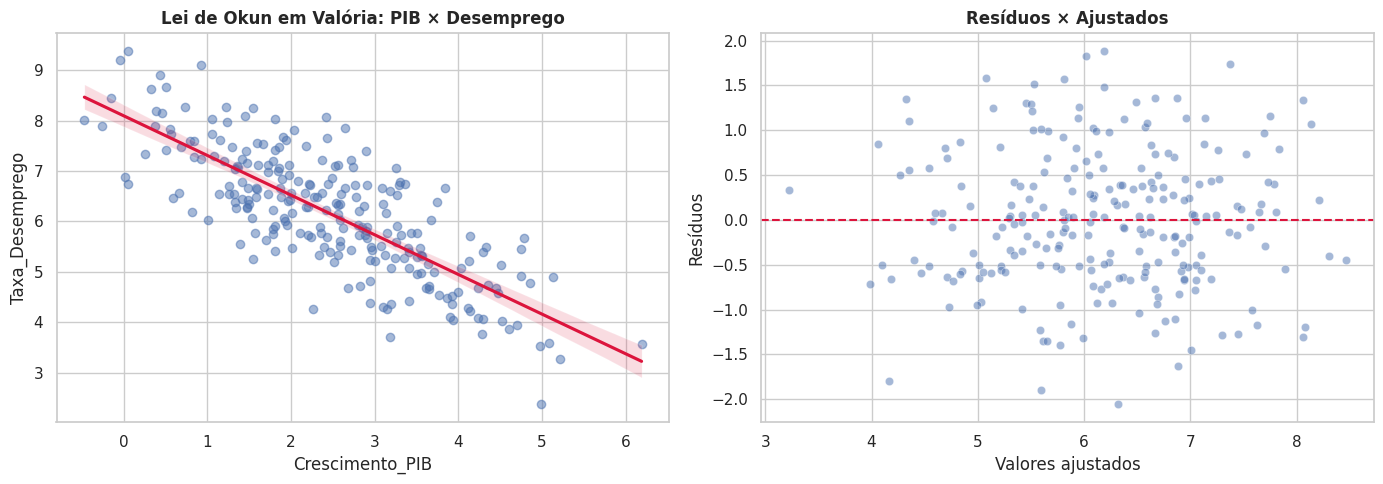

In [16]:
# ------------------------------------------------------------
# Módulo 5.1 – Regressão Linear Simples
# ------------------------------------------------------------
X = sm.add_constant(df['Crescimento_PIB'])
ols_s = sm.OLS(df['Taxa_Desemprego'], X).fit()
print(ols_s.summary())

print('\n--- Resumo ---')
print(f'β0 (intercepto) = {ols_s.params["const"]:.4f}')
print(f'β1 (Crescimento_PIB) = {ols_s.params["Crescimento_PIB"]:.4f} | IC95% = {ols_s.conf_int().loc["Crescimento_PIB"].round(4).tolist()}')
print(f'R² = {ols_s.rsquared:.4f} | R² ajustado = {ols_s.rsquared_adj:.4f}')
print(f'Teste F global: F = {ols_s.fvalue:.2f} | p = {ols_s.f_pvalue:.3e}')

# Conferência com scikit-learn
from sklearn.linear_model import LinearRegression
lr = LinearRegression().fit(df[['Crescimento_PIB']], df['Taxa_Desemprego'])
print(f'\nConferência sklearn → β0 = {lr.intercept_:.4f} | β1 = {lr.coef_[0]:.4f} | R² = {lr.score(df[["Crescimento_PIB"]], df["Taxa_Desemprego"]):.4f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.regplot(data=df, x='Crescimento_PIB', y='Taxa_Desemprego', scatter_kws={'alpha': .5}, line_kws={'color': 'crimson'}, ax=axes[0])
axes[0].set_title('Lei de Okun em Valória: PIB × Desemprego', fontweight='bold')
sns.scatterplot(x=ols_s.fittedvalues, y=ols_s.resid, alpha=.5, ax=axes[1])
axes[1].axhline(0, color='crimson', ls='--'); axes[1].set_xlabel('Valores ajustados'); axes[1].set_ylabel('Resíduos')
axes[1].set_title('Resíduos × Ajustados', fontweight='bold')
plt.tight_layout(); plt.show()

**Interpretação:** Ŷ = 8,095 − 0,787·X. Cada 1 p.p. adicional de crescimento do PIB está associado a uma **queda de ~0,79 p.p. na taxa de desemprego** (IC 95% ≈ [−0,866 ; −0,708]). R² = 0,618: o PIB explica ~62% da variabilidade do desemprego. Teste F global: F(1; 238) ≈ 384,3, **p ≈ 1,4 × 10⁻⁵¹** → rejeitamos H₀; o modelo é altamente significativo (relação do tipo “Lei de Okun”). O gráfico de resíduos não mostra padrão, indicando adequação da forma linear.

### 5.2 Regressão Linear Múltipla — `Investimento_Estrangeiro_Mi` (Y)
**Modelo:** Ŷ = β₀ + β₁·PIB + β₂·Inflação + β₃·Selic + β₄·Desemprego

* **Teste F global — H₀:** β₁ = β₂ = β₃ = β₄ = 0 · **H₁:** pelo menos um βⱼ ≠ 0.
* **Teste t individual — H₀:** βⱼ = 0 · **H₁:** βⱼ ≠ 0 (decisão com p < 0,05).

In [17]:
# ------------------------------------------------------------
# Módulo 5.2 – Regressão Linear Múltipla
# ------------------------------------------------------------
preditores = ['Crescimento_PIB', 'Inflacao', 'Taxa_Juros_Selic', 'Taxa_Desemprego']
Xm = sm.add_constant(df[preditores])
ols_m = sm.OLS(df['Investimento_Estrangeiro_Mi'], Xm).fit()
print(ols_m.summary())

# Equação ajustada
b = ols_m.params
print('\nEquação ajustada:')
print(f'Ŷ = {b["const"]:.4f} {b["Crescimento_PIB"]:+.4f}·X1 {b["Inflacao"]:+.4f}·X2 '
      f'{b["Taxa_Juros_Selic"]:+.4f}·X3 {b["Taxa_Desemprego"]:+.4f}·X4')
print('onde X1 = Crescimento_PIB, X2 = Inflacao, X3 = Taxa_Juros_Selic, X4 = Taxa_Desemprego')

# Tabela de significância individual (teste t)
sig = pd.DataFrame({'Coeficiente': ols_m.params, 'Erro-padrão': ols_m.bse,
                    't': ols_m.tvalues, 'p-valor': ols_m.pvalues})
sig['Significativo (p<0,05)?'] = np.where(sig['p-valor'] < ALPHA, 'SIM', 'NÃO')
display(sig.round(4))

print(f'R² = {ols_m.rsquared:.4f} | R² ajustado = {ols_m.rsquared_adj:.4f}')
print(f'Teste F global: F = {ols_m.fvalue:.2f} | p = {ols_m.f_pvalue:.3e}')

                                 OLS Regression Results                                
Dep. Variable:     Investimento_Estrangeiro_Mi   R-squared:                       0.814
Model:                                     OLS   Adj. R-squared:                  0.810
Method:                          Least Squares   F-statistic:                     256.6
Date:                         Thu, 22 Oct 2026   Prob (F-statistic):           1.75e-84
Time:                                 01:22:53   Log-Likelihood:                -890.68
No. Observations:                          240   AIC:                             1791.
Df Residuals:                              235   BIC:                             1809.
Df Model:                                    4                                         
Covariance Type:                     nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------

,Coeficiente,Erro-padrão,t,p-valor,"Significativo (p<0,05)?"
const,118.5888,8.8414,13.4129,0.0000,SIM
Crescimento_PIB,13.9110,0.8537,16.2953,0.0000,SIM
Inflacao,1.4689,1.5476,0.9491,0.3435,NÃO
Taxa_Juros_Selic,-3.7506,1.2671,-2.9601,0.0034,SIM
Taxa_Desemprego,-1.5760,0.8565,-1.8401,0.0670,NÃO


R² = 0.8137 | R² ajustado = 0.8105
Teste F global: F = 256.55 | p = 1.751e-84


In [18]:
# ------------------------------------------------------------
# Módulo 5.3 – Diagnóstico de Multicolinearidade (VIF)
# ------------------------------------------------------------
vif = pd.DataFrame({
    'Variável': preditores,
    'VIF': [variance_inflation_factor(Xm.values, i + 1) for i in range(len(preditores))]
})
vif['Diagnóstico'] = pd.cut(vif['VIF'], bins=[0, 5, 10, np.inf],
                            labels=['Baixa (<5)', 'Moderada (5–10)', 'SEVERA (>10)'])
display(vif.round(2))

,Variável,VIF,Diagnóstico
0,Crescimento_PIB,2.6600,Baixa (<5)
1,Inflacao,45.5500,SEVERA (>10)
2,Taxa_Juros_Selic,45.4300,SEVERA (>10)
3,Taxa_Desemprego,2.6800,Baixa (<5)


                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept          101.5351      2.015     50.386      0.000      97.565     105.505
Crescimento_PIB     15.1437      0.526     28.793      0.000      14.108      16.180
Taxa_Juros_Selic    -2.6103      0.189    -13.825      0.000      -2.982      -2.238
R² ajustado completo = 0.8105 | R² ajustado reduzido = 0.8088
AIC completo = 1791.4 | AIC reduzido = 1791.5

Shapiro dos resíduos (normalidade): p = 0.9112
Breusch-Pagan (homocedasticidade) : p = 0.4661


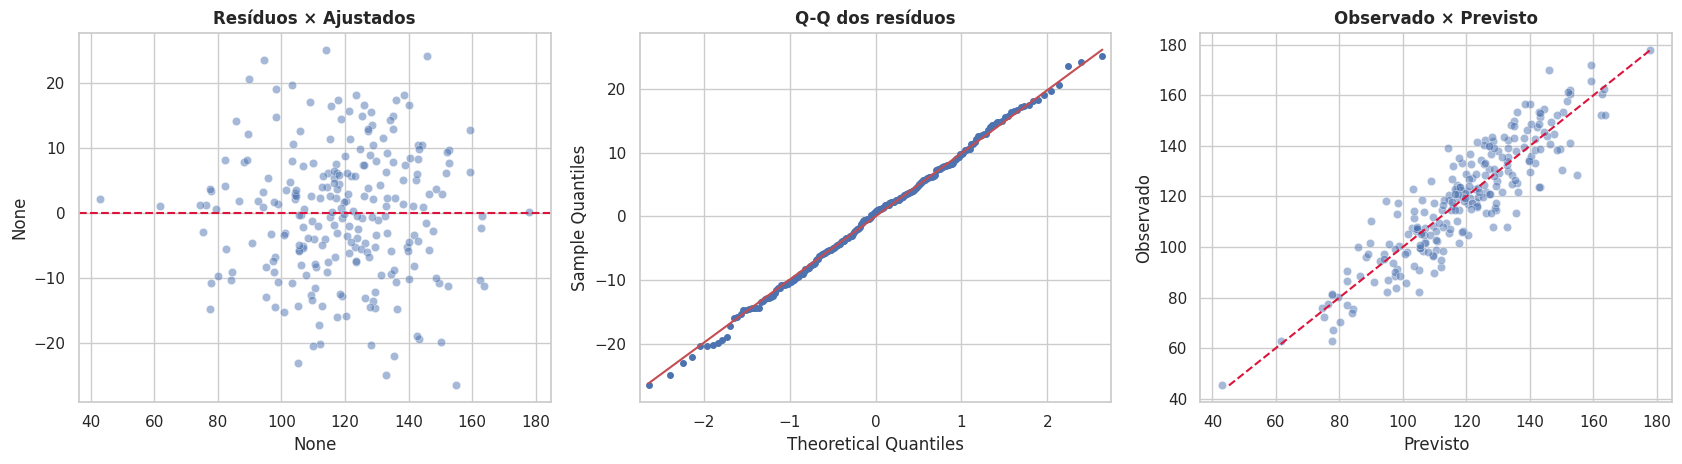

In [19]:
# ------------------------------------------------------------
# Módulo 5.4 – Modelo reduzido (tratamento da multicolinearidade) e diagnóstico de resíduos
# ------------------------------------------------------------
# Inflação e Selic são quase a mesma informação (r = 0,99). Mantém-se a Selic, que é o instrumento de política.
ols_r = smf.ols('Investimento_Estrangeiro_Mi ~ Crescimento_PIB + Taxa_Juros_Selic', data=df).fit()
print(ols_r.summary().tables[1])
print(f'R² ajustado completo = {ols_m.rsquared_adj:.4f} | R² ajustado reduzido = {ols_r.rsquared_adj:.4f}')
print(f'AIC completo = {ols_m.aic:.1f} | AIC reduzido = {ols_r.aic:.1f}')

# Diagnóstico de resíduos do modelo completo
from statsmodels.stats.diagnostic import het_breuschpagan
bp = het_breuschpagan(ols_m.resid, ols_m.model.exog)
print(f'\nShapiro dos resíduos (normalidade): p = {stats.shapiro(ols_m.resid)[1]:.4f}')
print(f'Breusch-Pagan (homocedasticidade) : p = {bp[1]:.4f}')

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
sns.scatterplot(x=ols_m.fittedvalues, y=ols_m.resid, alpha=.5, ax=axes[0])
axes[0].axhline(0, color='crimson', ls='--'); axes[0].set_title('Resíduos × Ajustados', fontweight='bold')
sm.qqplot(ols_m.resid, line='s', ax=axes[1], markersize=4); axes[1].set_title('Q-Q dos resíduos', fontweight='bold')
sns.scatterplot(x=ols_m.fittedvalues, y=df['Investimento_Estrangeiro_Mi'], alpha=.5, ax=axes[2])
lim = [df['Investimento_Estrangeiro_Mi'].min(), df['Investimento_Estrangeiro_Mi'].max()]
axes[2].plot(lim, lim, color='crimson', ls='--'); axes[2].set_title('Observado × Previsto', fontweight='bold')
axes[2].set_xlabel('Previsto'); axes[2].set_ylabel('Observado')
plt.tight_layout(); plt.show()

### Leitura do Módulo 5.2
* **Equação ajustada:** Ŷ = 118,589 + 13,911·X₁ + 1,469·X₂ − 3,751·X₃ − 1,576·X₄
* **Qualidade do ajuste:** R² = 0,814 e **R² ajustado = 0,810**; F(4; 235) ≈ 256,6, **p ≈ 0** → o modelo é globalmente significativo.
* **Testes t individuais (α = 5%):** `Crescimento_PIB` (t = 16,30; p < 0,001) ✔ e `Taxa_Juros_Selic` (t = −2,96; p = 0,003) ✔ são significativas. `Inflacao` (p = 0,344) e `Taxa_Desemprego` (p = 0,067) **não são significativas**.
* **VIF:** PIB ≈ 2,66 e Desemprego ≈ 2,68 (baixa); **Inflação ≈ 45,5 e Selic ≈ 45,4 (severa, > 10)**. A forte colinearidade entre Inflação e Selic infla os erros-padrão e explica o sinal “positivo” e não significativo da inflação (contraintuitivo): seu efeito já está capturado pela Selic.
* **Modelo reduzido (PIB + Selic):** Ŷ = 101,535 + 15,144·PIB − 2,610·Selic, com R² ajustado = 0,809, praticamente idêntico ao completo (0,810) e **todos os coeficientes com p < 0,001** — mais parcimonioso e estável.

### 6.0 Síntese automática dos resultados (conferência do informe)
A célula abaixo recalcula os números centrais a partir das saídas deste notebook. Ela serve para conferir que **todos os valores citados no informe** correspondem à execução atual.

In [20]:
# ------------------------------------------------------------
# 6.0 – Síntese automática (conferência dos números do informe)
# ------------------------------------------------------------
def dec(p): return 'Rejeita H0' if p < ALPHA else 'Não rejeita H0'
p_sw_pib, p_sw_inf = [r['p-valor'] for r in res_sw]
resumo = pd.DataFrame([
    ['Shapiro-Wilk – Crescimento_PIB',        p_sw_pib,                      dec(p_sw_pib)],
    ['Shapiro-Wilk – Inflacao',               p_sw_inf,                      dec(p_sw_inf)],
    ['Qui-Quadrado – regiões uniformes',      p_chi,                         dec(p_chi)],
    ['Levene – variância PIB (Antes×Depois)', lev_p,                         dec(lev_p)],
    ['t de Student – média PIB (Antes×Depois)', t_p,                         dec(t_p)],
    ['Mann-Whitney – Inflação (Sim×Nao)',     p_u,                           dec(p_u)],
    ['ANOVA 1 fator – Desemprego ~ Região',   tab1.loc['C(Regiao)', 'p-valor'], dec(tab1.loc['C(Regiao)', 'p-valor'])],
    ['ANOVA 2 fatores – interação',           tab2.loc['C(Regiao):C(Periodo_Politica)', 'p-valor'],
                                              dec(tab2.loc['C(Regiao):C(Periodo_Politica)', 'p-valor'])],
    ['Regressão simples – β1 (PIB→Desemprego)', ols_s.pvalues['Crescimento_PIB'], dec(ols_s.pvalues['Crescimento_PIB'])],
    ['Regressão múltipla – F global',         ols_m.f_pvalue,                dec(ols_m.f_pvalue)],
    ['Tendência temporal (menor p entre indicadores)', tendencia[['p (Pearson)', 'p (Spearman)']].min().min(),
                                              dec(tendencia[['p (Pearson)', 'p (Spearman)']].min().min())],
], columns=['Teste', 'p-valor', 'Decisão (α=0,05)']).set_index('Teste')
display(resumo)
print(f"Regressão simples: β1 = {ols_s.params['Crescimento_PIB']:.4f} | R² = {ols_s.rsquared:.4f}")
print(f"Regressão múltipla: R² ajustado = {ols_m.rsquared_adj:.4f} | VIF máx. = {vif['VIF'].max():.1f}")
print(f"Modelo reduzido (PIB + Selic): R² ajustado = {ols_r.rsquared_adj:.4f}")

,p-valor,"Decisão (α=0,05)"
Teste,,
Shapiro-Wilk – Crescimento_PIB,0.6223,Não rejeita H0
Shapiro-Wilk – Inflacao,0.0000,Rejeita H0
Qui-Quadrado – regiões uniformes,0.5519,Não rejeita H0
Levene – variância PIB (Antes×Depois),0.3146,Não rejeita H0
t de Student – média PIB (Antes×Depois),0.5373,Não rejeita H0
Mann-Whitney – Inflação (Sim×Nao),0.7684,Não rejeita H0
ANOVA 1 fator – Desemprego ~ Região,0.7433,Não rejeita H0
ANOVA 2 fatores – interação,0.4557,Não rejeita H0
Regressão simples – β1 (PIB→Desemprego),0.0000,Rejeita H0


Regressão simples: β1 = -0.7871 | R² = 0.6176
Regressão múltipla: R² ajustado = 0.8105 | VIF máx. = 45.5
Modelo reduzido (PIB + Selic): R² ajustado = 0.8088


---
# 6. INFORME EXECUTIVO — STORYTELLING COM DADOS
**Ao:** Excelentíssimo Senhor Ministro da Economia da República de Valória
**De:** Analista Estatístico, Banco Central de Valória
**Assunto:** Diagnóstico estatístico dos indicadores macroeconômicos, 2005–2024 (240 observações mensais)

---
## 1. Introdução Executiva
Senhor Ministro, o Conselho de Política Econômica solicitou um diagnóstico rigoroso sobre duas décadas de indicadores nacionais. Três perguntas orientaram a análise:

1. **A economia de Valória é estável e quais são suas regularidades?**
2. **A reforma da política monetária e a divisão regional mudaram os resultados econômicos?**
3. **O que de fato move o investimento estrangeiro, e que alavancas de política temos à disposição?**

**Resumo em três linhas:** (i) o crescimento é estável e simétrico, mas a inflação é assimétrica, com surtos ocasionais; (ii) **não encontramos evidência estatística de que a reforma ou a região tenham alterado crescimento, desemprego ou investimento**; (iii) o investimento estrangeiro é governado por **crescimento do PIB (efeito positivo)** e **juros (efeito negativo)**, e o modelo explica **81%** de sua variação.

## 2. Diagnóstico de Estabilidade e Tendências
**Crescimento e emprego são previsíveis.** O PIB cresce em média 2,46% ao mês, com desvio-padrão de 1,24 p.p. e distribuição simétrica; o teste de Shapiro-Wilk (p = 0,62) confirma que seu comportamento é compatível com a normalidade. O desemprego (média 6,16%) acompanha o PIB de perto: a correlação é de **−0,79**, e a regressão mostra que **cada ponto de crescimento adicional reduz o desemprego em ~0,79 p.p.** (R² = 62%).

**Não há tendência de longo prazo.** Testamos a correlação de cada indicador com o ano: nenhum é significativo (todos os p > 0,30 em Pearson e Spearman; |r| ≤ 0,07). Em duas décadas, crescimento, inflação, juros, desemprego e investimento **oscilam em torno de níveis estáveis, sem deriva** — a economia não está "melhorando" nem "piorando" de forma sistemática.

**A inflação é o ponto de atenção.** Média de 2,88%, mas mediana de 2,04%, assimetria de 1,66 e máximo de 17,3%: a inflação é “tranquila na maior parte do tempo”, mas sujeita a picos intensos (Shapiro-Wilk: p ≈ 10⁻¹⁵, rejeitada a normalidade). Como a Selic reage quase mecanicamente à inflação (correlação de **0,99**), os juros herdam essa assimetria — média de 7,50% e máximo de 24,9%.

**A amostra é equilibrada.** O teste de aderência (χ² = 2,10; p = 0,55) mostra que as quatro regiões estão igualmente representadas; portanto, as conclusões abaixo não decorrem de viés amostral.

## 3. Validação das Políticas Públicas
| Pergunta de política | Teste | Resultado | Conclusão |
|---|---|---|---|
| A reforma mudou a **volatilidade** do crescimento? | Levene | p = 0,315 | Não |
| A reforma mudou o **crescimento médio**? | t de Student | 2,51% vs. 2,41%; p = 0,537 | Não |
| Cumprir a meta está associado a **menor inflação**? | Mann-Whitney U | medianas 2,02 vs. 2,05; p = 0,768 | Não |
| Há **desigualdade regional** de desemprego? | ANOVA 1 fator | F = 0,41; p = 0,743 | Não |
| A reforma afetou o **investimento externo**, de forma diferente por região? | ANOVA 2 fatores | interação F = 0,87; p = 0,456 | Não |

**Leitura estratégica.** Todos os testes convergem: **a reforma da política monetária não deixou impressão estatisticamente detectável** em crescimento, volatilidade ou investimento externo, nem de forma geral, nem região a região. Dois cuidados: *(a)* ausência de evidência não é prova de ausência de efeito — diferenças pequenas exigiriam amostras maiores para serem detectadas; *(b)* a classificação “meta cumprida” **não se reflete na inflação medida**, o que sugere revisar o critério de apuração da meta. Em contrapartida, a homogeneidade regional é uma boa notícia: **não há regiões em desvantagem estrutural** de emprego ou de atratividade ao capital.

## 4. Modelo Preditivo Econométrico
Para explicar o investimento estrangeiro direto (US$ milhões), estimamos:

> **Ŷ = 118,59 + 13,91·PIB + 1,47·Inflação − 3,75·Selic − 1,58·Desemprego**   (R² ajustado = 0,810; F = 256,6; p < 0,001)

Como Inflação e Selic são quase redundantes (VIF ≈ 45), adotamos o **modelo parcimonioso** recomendado para uso em política:

> **Ŷ = 101,54 + 15,14·PIB − 2,61·Selic**   (R² ajustado = 0,809; todos os coeficientes com p < 0,001)

**Recomendações de política econômica**
1. **Priorizar o crescimento do PIB.** Cada 1 p.p. adicional de crescimento está associado a **~US$ 15 milhões a mais** de investimento estrangeiro (ceteris paribus) e, simultaneamente, a **~0,79 p.p. a menos de desemprego**. É a variável de maior impacto e de duplo dividendo.
2. **Calibrar a Selic com parcimônia.** Cada 1 p.p. a mais na Selic está associado a **~US$ 2,6 milhões a menos** de investimento. Como os juros acompanham a inflação, o controle de picos inflacionários protege indiretamente a atração de capital.
3. **Não esperar efeitos da reforma ou de políticas regionalizadas.** Sem diferenças detectáveis entre regiões ou períodos, recomenda-se foco em políticas de alcance nacional.
4. **Rever o critério da meta de inflação**, dado que seu cumprimento declarado não distingue meses de inflação maior ou menor.
5. **Evitar usar Inflação e Selic simultaneamente em modelos de previsão**; a colinearidade compromete a interpretação dos coeficientes.

**Limitações.** Valória e os dados são fictícios/simulados: os resultados ilustram métodos, não uma economia real. Os dados são mensais e as associações são condicionais, **não causais**; a atribuição de região, período de política e cumprimento da meta é independente das demais variáveis; o modelo assume linearidade e resíduos bem comportados (verificados graficamente e por Shapiro/Breusch-Pagan nas células acima). Recomenda-se reavaliação periódica com dados atualizados.

*Respeitosamente,*
*Analista Estatístico – Banco Central da República de Valória*